In [18]:
%pip install dtreeviz

Note: you may need to restart the kernel to use updated packages.


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import tree
from sklearn.datasets import load_iris, fetch_california_housing
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
import dtreeviz

In [20]:
clas = tree.DecisionTreeClassifier()
iris = load_iris()

X_train = iris.data
y_train = iris.target
clas.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curre

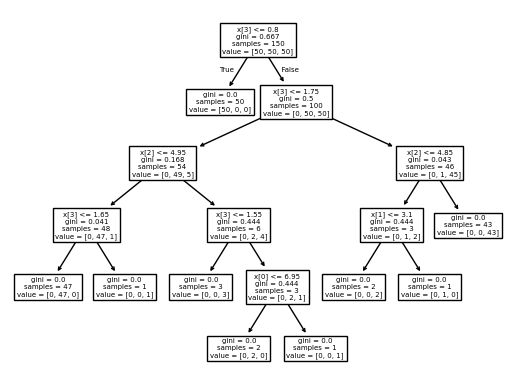

In [21]:
plot_tree(clas)
plt.show()

## classification viz

In [22]:
viz_model = dtreeviz.model(clas,
               X_train, y_train,
               feature_names=iris.feature_names,
               target_name="species",
               class_names=["setosa", "versicolor", "virginica"])
viz = viz_model.view()
viz

ExecutableNotFound: failed to execute 'dot', make sure the Graphviz executables are on your systems' PATH

In [23]:
# now tihs 
regr = tree.DecisionTreeRegressor(max_depth=1)
california = fetch_california_housing()

X_train_r = california.data
y_train_r = california.target
regr.fit(X_train_r, y_train_r)

viz_model_r = dtreeviz.model(regr,
               X_train_r, y_train_r,
               target_name='price',
               feature_names=california.feature_names)
viz = viz_model_r.view(scale=2)
viz

ExecutableNotFound: failed to execute 'dot', make sure the Graphviz executables are on your systems' PATH

# horizental tree

In [24]:
viz_model = dtreeviz.model(clas,
               X_train, y_train,
               target_name='species',
               feature_names=iris.feature_names,
               class_names=["setosa", "versicolor", "virginica"])
viz = viz_model.view(scale=1.5, orientation='LR')
viz

ExecutableNotFound: failed to execute 'dot', make sure the Graphviz executables are on your systems' PATH

# Show prediction path

In [25]:
X = iris.data[np.random.randint(0, len(iris.data)), :]

viz_model = dtreeviz.model(clas,
               X_train, y_train,
               feature_names=iris.feature_names,
               class_names=["setosa", "versicolor", "virginica"])
viz = viz_model.view(x=X)
viz

ExecutableNotFound: failed to execute 'dot', make sure the Graphviz executables are on your systems' PATH

# Node number 

In [26]:
viz_model = dtreeviz.model(clas,
               X_train, y_train,
               target_name='species',
               feature_names=iris.feature_names,
               class_names=["setosa", "versicolor", "virginica"])
viz = viz_model.view(scale=1.5, orientation='LR', show_node_labels=True)
viz

ExecutableNotFound: failed to execute 'dot', make sure the Graphviz executables are on your systems' PATH

# without fancy graph 

In [27]:
viz_model = dtreeviz.model(clas,
               X_train, y_train,
               target_name='species',
               feature_names=iris.feature_names,
               class_names=["setosa", "versicolor", "virginica"])
viz = viz_model.view(scale=1.5, orientation='LR', fancy=False)
viz

ExecutableNotFound: failed to execute 'dot', make sure the Graphviz executables are on your systems' PATH

# Just prediction path

In [28]:
X = iris.data[np.random.randint(0, len(iris.data)), :]

viz_model = dtreeviz.model(clas,
               X_train, y_train,
               target_name='species',
               feature_names=iris.feature_names,
               class_names=["setosa", "versicolor", "virginica"])
viz = viz_model.view(x=X, show_just_path=True)
viz

ExecutableNotFound: failed to execute 'dot', make sure the Graphviz executables are on your systems' PATH

In [29]:
print(viz_model.explain_prediction_path(x=X))

4.85 <= petal length (cm) 
1.75 <= petal width (cm) 



In [30]:
df_cars = pd.read_csv("cars.csv")
X_uni, y_uni = df_cars[['WGT']], df_cars['MPG']

dt = DecisionTreeRegressor(max_depth=3)
dt.fit(X_uni, y_uni)

viz_model_uni = dtreeviz.model(dt, X_uni, y_uni,
               feature_names=['WGT'], target_name='MPG')
fig = plt.figure()
ax = fig.gca()
viz_model_uni.rtree_feature_space(fontsize=10, ax=ax)
plt.show()

KeyError: "None of [Index(['WGT'], dtype='object')] are in the [columns]"